# Lab 11: Attention


### Attention is a mechanism that allows a neural network to focus more on relevant information when making a prediction.

Encoder-decoder architecture with attention:
<img src="https://drive.google.com/thumbnail?id=1-QeHdZIeKTo_nAqfh7pRA_o4Nk8CAmP6&sz=w1000" width="700">

## Step 1 — Import libraries

In [1]:
import pandas as pd
import torch
from torch import nn
import matplotlib.pyplot as plt

torch.manual_seed(42)

## Step 2 — Upload the dataset

In [2]:
df = pd.read_csv("Lab_11_QnA_Dataset.csv")
print("Number of questions:", len(df))
print("Number of answer groups:", df["answer_id"].nunique())
display(df.head())


Number of questions: 168
Number of answer groups: 12


,question,answer_id,answer
0,Do you get hurt?,0,I don't have a body.
1,Do you have fingers?,0,I don't have a body.
2,Do you ever breathe,0,I don't have a body.
3,Do you masticate?,0,I don't have a body.
4,Can you throw up?,0,I don't have a body.


## Step 3 — Preprocessing

1. Lowercase each question and remove punctuation.
2. Give each word a number.
3. Make all questions the same length by adding zeros (**padding**).

In [3]:
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences

# 1. Lowercase
df["question"] = df["question"].str.lower()

# 2. Tokenization
tokenizer = Tokenizer()
tokenizer.fit_on_texts(df["question"])

# Convert words to numbers and add padding
X = pad_sequences(tokenizer.texts_to_sequences(df["question"]), padding="post")

# Answers
y = df["answer_id"].values

# Convert to PyTorch tensors
X = torch.tensor(X, dtype=torch.long)
y = torch.tensor(y, dtype=torch.long)

## Step 4 — Build an RNN with attention

- **Embedding** turns word numbers into vectors.
- **RNN** reads the words in sequence.
- **Attention** gives each word a weight.
- **Output** chooses one answer from the dataset.

In [13]:
class RNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.emb = nn.Embedding(len(tokenizer.word_index) + 1, 16)
        self.rnn = nn.RNN(16, 32, batch_first=True)
        self.att = nn.Linear(32, 1)
        self.fc = nn.Linear(32, df["answer_id"].nunique())

    def forward(self, x):
        x, _ = self.rnn(self.emb(x))
        weights = torch.softmax(self.att(x), dim=1)
        return self.fc((x * weights).sum(1)), weights.squeeze(-1)

model = RNN()

## Step 5 — Train the model
The model learns which answer belongs to each question.

In [14]:
optimizer = torch.optim.Adam(model.parameters(), lr=0.01)

for epoch in range(50):
    optimizer.zero_grad()
    loss = nn.functional.cross_entropy(model(X)[0], y) #calculate loss to reduce it
    loss.backward() #backpropagation to update parameters
    optimizer.step() #update parameters

print("Training finished!")

Training finished!


## Step 6 — See attention
The bar chart shows how much attention the model gives to each question word.

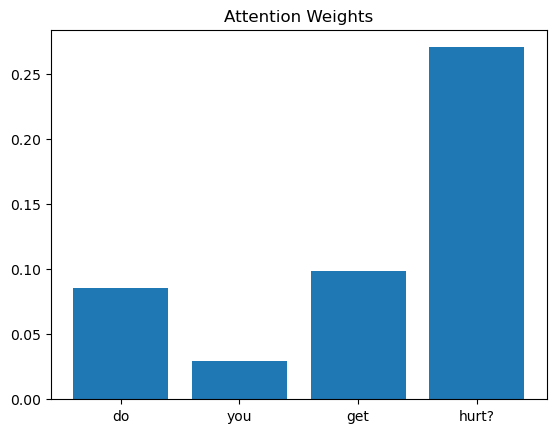

In [15]:
question = df["question"][0]
words = question.split()

with torch.no_grad():
    prediction, weights = model(X[:1])

plt.bar(words, weights[0, :len(words)].tolist())
plt.title("Attention Weights")
plt.show()

## Tasks:


Task 1 — Understand Attention Weights
Easy

Modify Step 6 to visualize the attention weights for three different questions from the dataset instead of only the first question.

Instructions:
- Select three questions from the dataset.
- Generate an attention bar chart for each question.
- Identify the word receiving the highest attention weight in each question.

Question: Do the words with the highest attention weights appear important for understanding the question? Explain your observations.

In [16]:
def plot_attention(indices, title):
    model.eval()
    results = []

    fig, axes = plt.subplots(
        len(indices), 1,
        figsize=(10, 3.5 * len(indices)),
        squeeze=False
    )

    for row, idx in enumerate(indices):
        # Get the actual tokens used by your notebook.
        if "tokenizer" in globals():
            words = tokenizer.sequences_to_texts(
                [X[idx].tolist()]
            )[0].split()
        else:
            words = word_lists[idx]

        with torch.no_grad():
            prediction, weights = model(X[idx:idx + 1])

        values = weights[0, :len(words)].tolist()
        highest = values.index(max(values))

        ax = axes[row, 0]
        ax.bar(range(len(words)), values)
        ax.set_xticks(range(len(words)))
        ax.set_xticklabels(words, rotation=30, ha="right")
        ax.set_title(df.iloc[idx]["question"])
        ax.set_ylabel("Attention weight")

        results.append({
            "question": df.iloc[idx]["question"],
            "highest_attention_word": words[highest],
            "weight": values[highest]
        })

    fig.suptitle(title)
    plt.tight_layout(rect=[0, 0, 1, 0.96])
    plt.show()

    return pd.DataFrame(results)

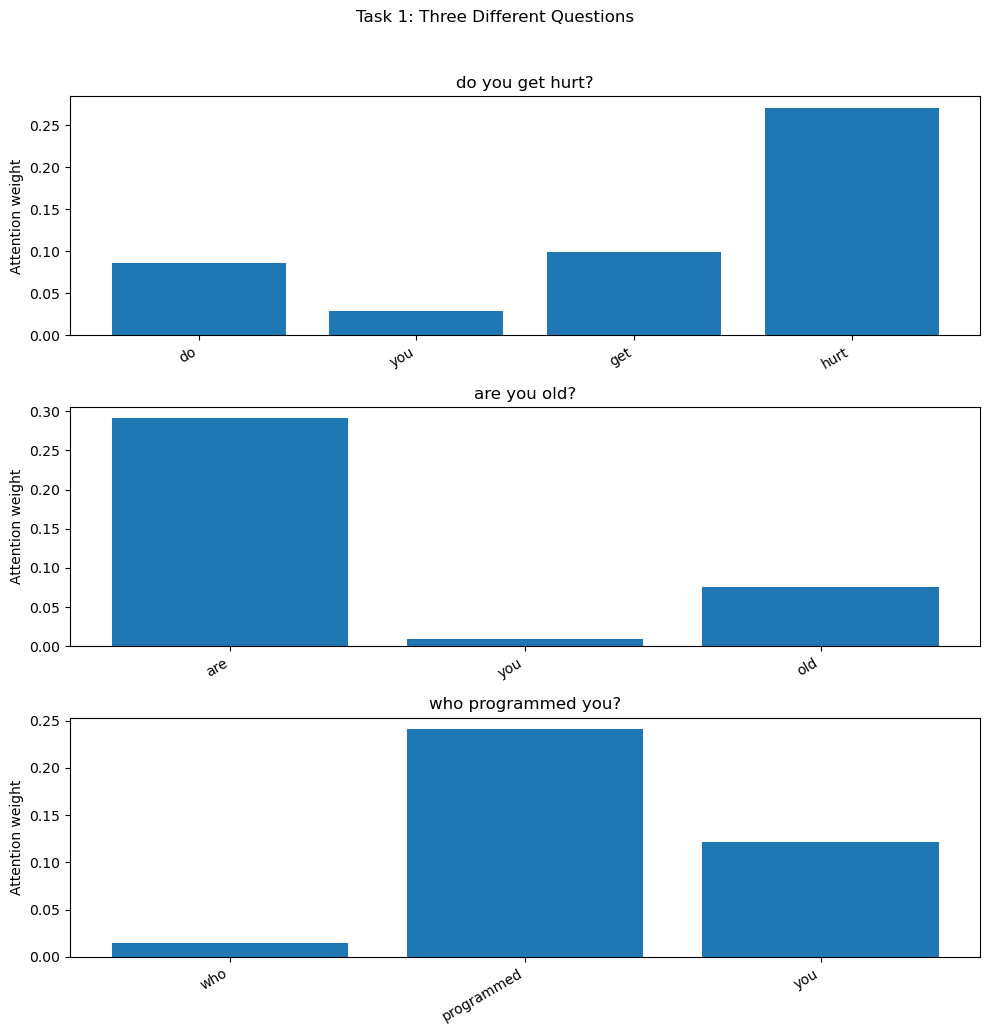

Question: do you get hurt? | Highest attention: hurt (0.271)
Question: are you old? | Highest attention: are (0.291)
Question: who programmed you? | Highest attention: programmed (0.241)


In [17]:
# Three questions covering different answer groups.
task1_indices = [0, int(df.index[df["answer_id"] == 1][0]),
                 int(df.index[df["answer_id"] == 3][0])]
task1_results = plot_attention(task1_indices, "Task 1: Three Different Questions")
for row in task1_results.itertuples(index=False):
    print(f'Question: {row.question} | Highest attention: {row.highest_attention_word} ({row.weight:.3f})')

“Hurt” and “programmed” are important for understanding the questions, while “are” is less informative on its own. This shows that the highest attention weight does not always identify the most meaningful word.

Task 2 — Compare Attention for Similar Questions
Medium

Select two questions from the dataset that have similar meanings but different wording.

Instructions:
- Pass both questions through the trained model.
- Visualize their attention weights.
- Compare the words receiving the highest attention weights.

Question: Does the model focus on similar or different words when processing questions with similar meanings? What does this suggest about how attention works?

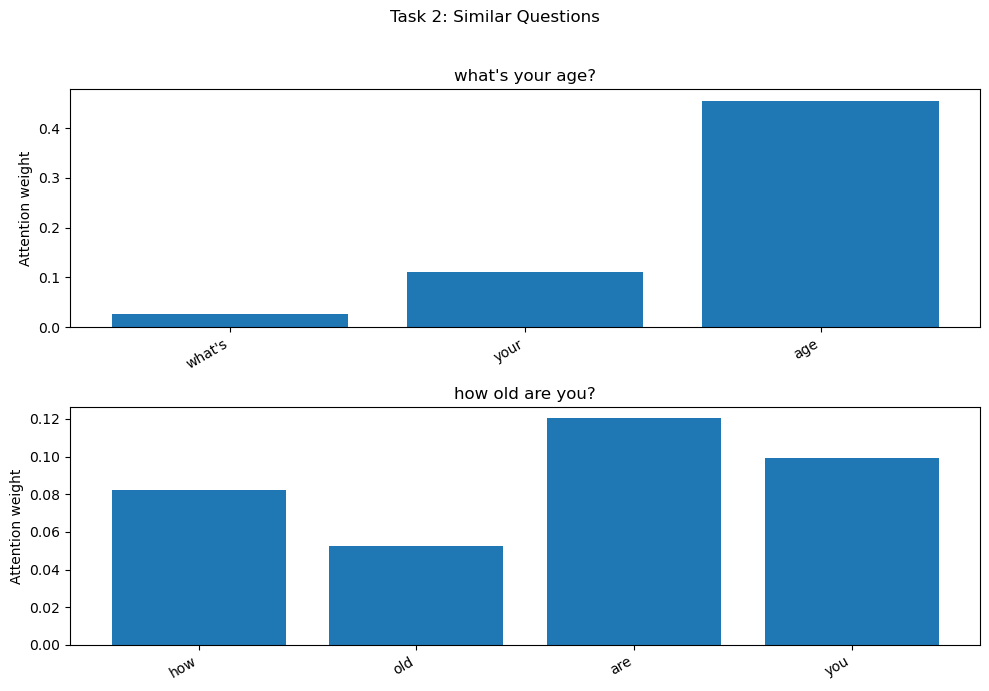

Question: what's your age? | Highest attention: age (0.455)
Question: how old are you? | Highest attention: are (0.120)
The model focuses on different words.


In [18]:
selected_questions = ["what's your age?", "how old are you?"]

questions = df["question"].str.lower().str.strip()

task2_indices = [
    int(df.index[questions == q][0])
    for q in selected_questions
]

assert df.loc[task2_indices, "answer_id"].nunique() == 1

task2_results = plot_attention(
    task2_indices,
    "Task 2: Similar Questions"
)

for row in task2_results.itertuples(index=False):
    print(
        f"Question: {row.question} | "
        f"Highest attention: {row.highest_attention_word} "
        f"({row.weight:.3f})"
    )

first, second = task2_results["highest_attention_word"].tolist()

print(
    "The model focuses on",
    "the same word." if first == second else "different words."
)

The model focuses on “age” (0.455) and “are” (0.120). This shows that similar questions can receive different attention weights depending on context.